# U-Net frente a DeepLab: segmentar peatones

**Qué harás.** Entrenarás dos redes de segmentación pequeñas, una U-Net y una versión reducida de DeepLab, sobre el mismo conjunto de fotos reales de calles con peatones. Las dos reciben los mismos datos, la misma función de pérdida y el mismo número de épocas. Lo único que cambia es la arquitectura.

**Qué obtendrás.** Una tabla con parámetros, tiempo e IoU en imágenes que las redes nunca vieron, una animación (GIF) que muestra cómo cada red va dibujando la máscara época a época, y una comparación de errores.

**Cuánto tarda.** Unos 3 a 5 minutos en CPU (sin GPU). Funciona en Colab o en un computador portátil.

**Glosario (se define aquí por primera vez).**
- *Segmentación semántica*: clasificar cada píxel de la imagen (aquí: persona o fondo).
- *Máscara*: imagen en blanco y negro donde 1 significa "persona" y 0 "fondo".
- *IoU* (intersección sobre unión): área donde la máscara predicha y la real coinciden, dividida por el área que cubren entre las dos. Va de 0 (nada) a 1 (perfecto).
- *Skip connection* (conexión de salto): copia de un mapa de características del codificador que se pega al decodificador para recuperar detalle fino. Es la idea central de la U-Net.
- *Convolución dilatada (atrous)*: convolución con huecos entre los pesos; ve un área más grande sin más parámetros ni perder resolución. Es la idea central de DeepLab.
- *ASPP*: varias convoluciones dilatadas con distintas tasas en paralelo, para mirar a varias escalas a la vez.

  

## 1. Instalación y semilla
Necesitas `torch`, `numpy`, `matplotlib` y `pillow`. En Colab ya están. En local: `pip install torch numpy matplotlib pillow` (versión CPU).

In [1]:
import os, time, zipfile, urllib.request, random
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
torch.set_num_threads(max(1, os.cpu_count() or 1))
print('torch', torch.__version__, '| hilos CPU:', torch.get_num_threads())

torch 2.14.1+cpu | hilos CPU: 2


## 2. Datos reales: Penn-Fudan Pedestrian
170 fotos de calles de Pensilvania con peatones, con la máscara dibujada a mano de cada persona (Wang et al., 2007). Pesa unos 50 MB. Convertimos todas las máscaras en una sola: **persona = 1, fondo = 0**, y reducimos las imágenes a 128 x 128 píxeles para que entrene rápido.

Descargando (~50 MB)...
Entrenamiento: 136 imágenes | Prueba (nunca vistas): 34
Fracción de píxeles que son persona: 17.3%  (por eso el IoU es mejor medida que la exactitud)


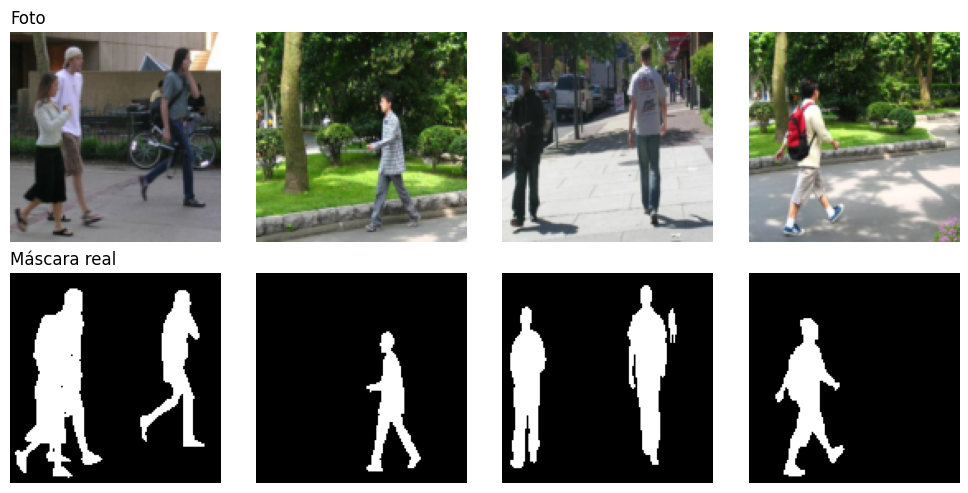

In [2]:
URL = 'https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip'
if not os.path.exists('PennFudanPed'):
    print('Descargando (~50 MB)...')
    urllib.request.urlretrieve(URL, 'PennFudanPed.zip')
    zipfile.ZipFile('PennFudanPed.zip').extractall('.')

T = 128
nombres = sorted(f[:-4] for f in os.listdir('PennFudanPed/PNGImages') if f.endswith('.png'))
X = np.zeros((len(nombres), 3, T, T), np.float32)
Y = np.zeros((len(nombres), 1, T, T), np.float32)
for i, n in enumerate(nombres):
    im = Image.open(f'PennFudanPed/PNGImages/{n}.png').convert('RGB').resize((T, T), Image.BILINEAR)
    mk = Image.open(f'PennFudanPed/PedMasks/{n}_mask.png').resize((T, T), Image.NEAREST)
    X[i] = np.asarray(im, np.float32).transpose(2, 0, 1) / 255.0
    Y[i, 0] = (np.asarray(mk) > 0)
media, desv = X.mean((0, 2, 3), keepdims=True), X.std((0, 2, 3), keepdims=True)
Xn = (X - media) / desv

rng = np.random.RandomState(SEMILLA); orden = rng.permutation(len(nombres))
n_test = 34
idx_test, idx_train = orden[:n_test], orden[n_test:]
Xtr, Ytr = torch.tensor(Xn[idx_train]), torch.tensor(Y[idx_train])
Xte, Yte = torch.tensor(Xn[idx_test]), torch.tensor(Y[idx_test])
print(f'Entrenamiento: {len(idx_train)} imágenes | Prueba (nunca vistas): {len(idx_test)}')
print(f'Fracción de píxeles que son persona: {Y.mean():.1%}  (por eso el IoU es mejor medida que la exactitud)')

fig, ax = plt.subplots(2, 4, figsize=(10, 5))
for j in range(4):
    k = idx_test[j]
    ax[0, j].imshow(X[k].transpose(1, 2, 0)); ax[1, j].imshow(Y[k, 0], cmap='gray')
    ax[0, j].axis('off'); ax[1, j].axis('off')
ax[0, 0].set_title('Foto', loc='left'); ax[1, 0].set_title('Máscara real', loc='left')
plt.tight_layout(); plt.show()

## 3. Las dos redes
Las dos son versiones pequeñas (menos canales) para que entrenen en CPU. Se mantiene la **idea de cada arquitectura**:

| | U-Net (Ronneberger et al., 2015) | DeepLabv3+ reducida (Chen et al., 2018) |
|---|---|---|
| Cómo recupera la resolución | Decodificador simétrico: sube de a 2x y pega skip connections de cada nivel | El codificador baja solo hasta 1/8 y usa convoluciones dilatadas; el decodificador sube de 1/8 a 1/4 y de ahí a la resolución original |
| Cómo ve el contexto | Bajando mucho (1/16) con max-pooling | ASPP: convoluciones dilatadas con tasas 1, 2 y 4 más promedio global de la imagen |
| Skip connections | En todos los niveles (4) | Una sola, desde 1/4 |

In [3]:
def bloque(i, o, d=1):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=d, dilation=d, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(s, c=16):
        super().__init__()
        s.e1 = nn.Sequential(bloque(3, c), bloque(c, c))
        s.e2 = nn.Sequential(bloque(c, 2*c), bloque(2*c, 2*c))
        s.e3 = nn.Sequential(bloque(2*c, 4*c), bloque(4*c, 4*c))
        s.e4 = nn.Sequential(bloque(4*c, 8*c), bloque(8*c, 8*c))
        s.u3 = nn.ConvTranspose2d(8*c, 4*c, 2, 2); s.d3 = nn.Sequential(bloque(8*c, 4*c), bloque(4*c, 4*c))
        s.u2 = nn.ConvTranspose2d(4*c, 2*c, 2, 2); s.d2 = nn.Sequential(bloque(4*c, 2*c), bloque(2*c, 2*c))
        s.u1 = nn.ConvTranspose2d(2*c, c, 2, 2);   s.d1 = nn.Sequential(bloque(2*c, c), bloque(c, c))
        s.sal = nn.Conv2d(c, 1, 1)
    def forward(s, x):
        a = s.e1(x)                      # 128x128
        b = s.e2(F.max_pool2d(a, 2))     # 64x64
        c_ = s.e3(F.max_pool2d(b, 2))    # 32x32
        d = s.e4(F.max_pool2d(c_, 2))    # 16x16 (cuello de botella)
        y = s.d3(torch.cat([s.u3(d), c_], 1))
        y = s.d2(torch.cat([s.u2(y), b], 1))
        y = s.d1(torch.cat([s.u1(y), a], 1))
        return s.sal(y)

class ASPP(nn.Module):
    def __init__(s, i, o, tasas=(1, 2, 4)):
        super().__init__()
        s.ramas = nn.ModuleList([nn.Sequential(nn.Conv2d(i, o, 1 if r == 1 else 3, padding=0 if r == 1 else r,
                                                         dilation=r, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True)) for r in tasas])
        s.glob = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(i, o, 1, bias=False), nn.ReLU(inplace=True))
        s.mezcla = nn.Sequential(nn.Conv2d(o*(len(tasas)+1), o, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(s, x):
        g = F.interpolate(s.glob(x), size=x.shape[2:], mode='bilinear', align_corners=False)
        return s.mezcla(torch.cat([r(x) for r in s.ramas] + [g], 1))

class DeepLabMini(nn.Module):
    def __init__(s, c=16):
        super().__init__()
        s.stem = nn.Sequential(nn.Conv2d(3, c, 3, 2, 1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True), bloque(c, c))   # 1/2
        s.b2 = nn.Sequential(nn.Conv2d(c, 2*c, 3, 2, 1, bias=False), nn.BatchNorm2d(2*c), nn.ReLU(inplace=True), bloque(2*c, 2*c))  # 1/4 (bajo nivel)
        s.b3 = nn.Sequential(nn.Conv2d(2*c, 4*c, 3, 2, 1, bias=False), nn.BatchNorm2d(4*c), nn.ReLU(inplace=True), bloque(4*c, 4*c))  # 1/8
        s.dil = nn.Sequential(bloque(4*c, 8*c, d=2), bloque(8*c, 8*c, d=4))   # sigue en 1/8 pero con campo receptivo grande
        s.aspp = ASPP(8*c, 4*c)
        s.bajo = nn.Sequential(nn.Conv2d(2*c, c, 1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True))
        s.dec = nn.Sequential(bloque(4*c + c, 2*c), bloque(2*c, 2*c))
        s.sal = nn.Conv2d(2*c, 1, 1)
    def forward(s, x):
        H, W = x.shape[2:]
        bajo = s.b2(s.stem(x))                       # 1/4
        y = s.aspp(s.dil(s.b3(bajo)))                # 1/8
        y = F.interpolate(y, size=bajo.shape[2:], mode='bilinear', align_corners=False)
        y = s.dec(torch.cat([y, s.bajo(bajo)], 1))   # 1/4
        return F.interpolate(s.sal(y), size=(H, W), mode='bilinear', align_corners=False)

def n_param(m): return sum(p.numel() for p in m.parameters())
redes = {'U-Net': UNet(), 'DeepLab': DeepLabMini()}
for k, m in redes.items():
    print(f'{k:8s} parámetros: {n_param(m):>9,}   salida: {tuple(m(Xtr[:1]).shape)}')

U-Net    parámetros:   482,737   salida: (1, 1, 128, 128)
DeepLab  parámetros:   507,697   salida: (1, 1, 128, 128)


## 4. Entrenamiento (las dos redes, época a época)
- **Pérdida**: entropía cruzada binaria + Dice. La entropía cruzada penaliza cada píxel mal clasificado; Dice (1 menos el solapamiento relativo) ayuda porque las personas ocupan pocos píxeles.
- **Aumento de datos**: volteo horizontal al azar (duplica la variedad sin fotos nuevas).
- **Optimizador**: Adam, tasa 3e-3. Lotes de 8 imágenes.
- Después de cada época guardamos la predicción de 4 imágenes de prueba para armar el GIF.

Cambia `EPOCAS` si quieres más precisión (más tiempo) o menos tiempo.

In [4]:
EPOCAS = 30
LOTE = 8
def perdida(logit, y):
    bce = F.binary_cross_entropy_with_logits(logit, y)
    p = torch.sigmoid(logit)
    dice = 1 - (2*(p*y).sum((1, 2, 3)) + 1) / (p.sum((1, 2, 3)) + y.sum((1, 2, 3)) + 1)
    return bce + dice.mean()

@torch.no_grad()
def evaluar(m, X, Y):
    m.eval(); P = torch.cat([torch.sigmoid(m(X[i:i+16])) for i in range(0, len(X), 16)])
    pred = (P > 0.5).float()
    inter = (pred*Y).sum((1, 2, 3)); union = ((pred+Y) > 0).float().sum((1, 2, 3))
    iou = (inter/(union+1e-6)).mean().item()
    return iou, P

vis = list(range(4))                      # imágenes de prueba para la animación
hist = {k: {'iou': [], 'perd': [], 'seg': 0.0} for k in redes}
cuadros = {k: [] for k in redes}          # predicciones por época
opts = {k: torch.optim.Adam(m.parameters(), lr=3e-3) for k, m in redes.items()}
torch.manual_seed(SEMILLA)

for ep in range(1, EPOCAS+1):
    perm = torch.randperm(len(Xtr))
    for k, m in redes.items():
        t0 = time.time(); m.train(); tot = 0
        for i in range(0, len(perm), LOTE):
            b = perm[i:i+LOTE]; x, y = Xtr[b], Ytr[b]
            if random.random() < 0.5: x, y = x.flip(3), y.flip(3)
            opts[k].zero_grad(); l = perdida(m(x), y); l.backward(); opts[k].step(); tot += l.item()*len(b)
        hist[k]['seg'] += time.time() - t0
        iou, P = evaluar(m, Xte, Yte)
        hist[k]['iou'].append(iou); hist[k]['perd'].append(tot/len(Xtr))
        cuadros[k].append(P[vis].squeeze(1).numpy())
    if ep == 1 or ep % 5 == 0:
        print(f'época {ep:2d} | ' + ' | '.join(f"{k}: pérdida {hist[k]['perd'][-1]:.3f}, IoU prueba {hist[k]['iou'][-1]:.3f}" for k in redes))
print()
for k in redes: print(f"{k:8s} tiempo de entrenamiento: {hist[k]['seg']/60:.1f} min")

época  1 | U-Net: pérdida 1.240, IoU prueba 0.347 | DeepLab: pérdida 1.146, IoU prueba 0.374
época  5 | U-Net: pérdida 0.678, IoU prueba 0.493 | DeepLab: pérdida 0.618, IoU prueba 0.500
época 10 | U-Net: pérdida 0.494, IoU prueba 0.589 | DeepLab: pérdida 0.472, IoU prueba 0.554
época 15 | U-Net: pérdida 0.425, IoU prueba 0.539 | DeepLab: pérdida 0.393, IoU prueba 0.568
época 20 | U-Net: pérdida 0.376, IoU prueba 0.637 | DeepLab: pérdida 0.325, IoU prueba 0.620
época 25 | U-Net: pérdida 0.316, IoU prueba 0.607 | DeepLab: pérdida 0.277, IoU prueba 0.613
época 30 | U-Net: pérdida 0.298, IoU prueba 0.641 | DeepLab: pérdida 0.250, IoU prueba 0.615

U-Net    tiempo de entrenamiento: 6.4 min
DeepLab  tiempo de entrenamiento: 1.9 min


## 5. Resultados: tabla y curvas

Red       Parámetros  Tiempo (min)  IoU final  Mejor IoU
U-Net        482,737           6.4      0.641      0.679
DeepLab      507,697           1.9      0.615      0.620


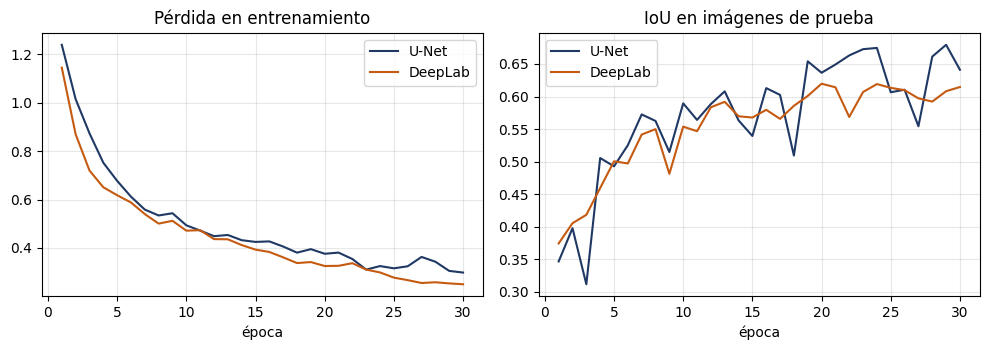

In [5]:
print(f"{'Red':8s} {'Parámetros':>11s} {'Tiempo (min)':>13s} {'IoU final':>10s} {'Mejor IoU':>10s}")
for k, m in redes.items():
    print(f"{k:8s} {n_param(m):>11,} {hist[k]['seg']/60:>13.1f} {hist[k]['iou'][-1]:>10.3f} {max(hist[k]['iou']):>10.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
col = {'U-Net': '#1F3864', 'DeepLab': '#C55A11'}
for k in redes:
    ax[0].plot(range(1, EPOCAS+1), hist[k]['perd'], color=col[k], label=k)
    ax[1].plot(range(1, EPOCAS+1), hist[k]['iou'], color=col[k], label=k)
ax[0].set_title('Pérdida en entrenamiento'); ax[1].set_title('IoU en imágenes de prueba')
for a in ax: a.set_xlabel('época'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. La animación: cómo cada red va dibujando la máscara
Cada fila es una imagen de prueba que **la red nunca usó para aprender**. Se muestra la probabilidad de "persona" que predice cada red al terminar cada época (blanco = seguro de que es persona). Se guarda como `unet_vs_deeplab.gif`.

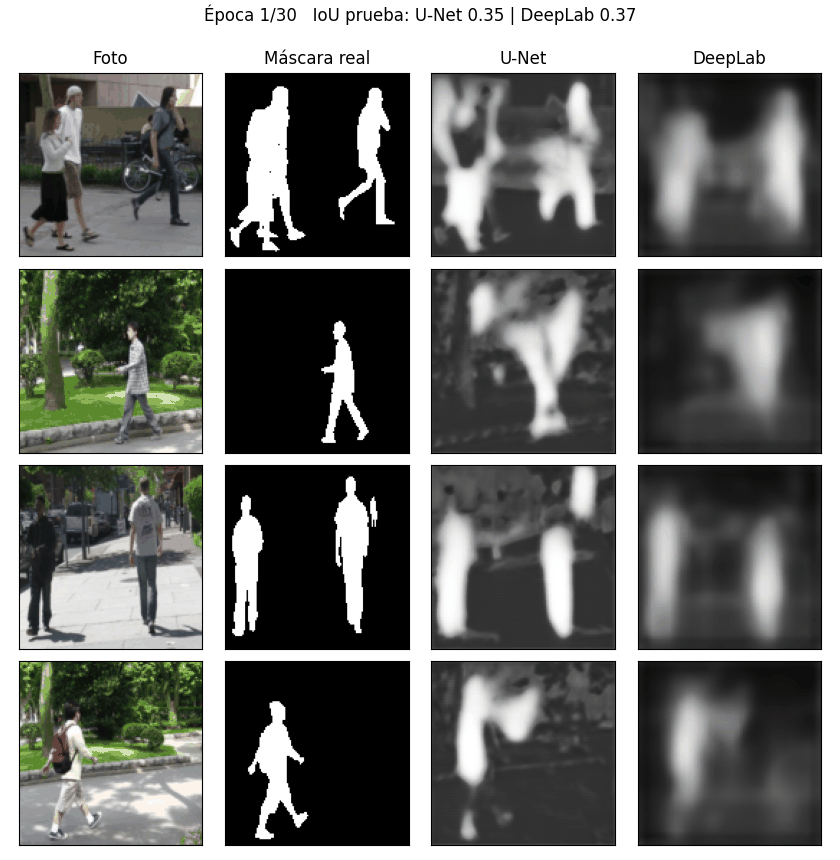

GIF guardado: /content/unet_vs_deeplab.gif


In [6]:
from matplotlib.animation import FuncAnimation, PillowWriter
fig, ax = plt.subplots(len(vis), 4, figsize=(8.4, 8.6))
titulos = ['Foto', 'Máscara real', 'U-Net', 'DeepLab']
ims = []
for r, k in enumerate(vis):
    foto = X[idx_test[k]].transpose(1, 2, 0)
    ax[r, 0].imshow(foto); ax[r, 1].imshow(Y[idx_test[k], 0], cmap='gray', vmin=0, vmax=1)
    a = ax[r, 2].imshow(cuadros['U-Net'][0][r], cmap='gray', vmin=0, vmax=1)
    b = ax[r, 3].imshow(cuadros['DeepLab'][0][r], cmap='gray', vmin=0, vmax=1)
    ims.append((a, b))
    for c in range(4): ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
for c in range(4): ax[0, c].set_title(titulos[c], fontsize=12)
txt = fig.suptitle('', fontsize=12, x=0.5, y=0.995)
plt.tight_layout(rect=(0, 0, 1, 0.975))
def cuadro(e):
    for r, (a, b) in enumerate(ims):
        a.set_data(cuadros['U-Net'][e][r]); b.set_data(cuadros['DeepLab'][e][r])
    txt.set_text(f"Época {e+1}/{EPOCAS}   IoU prueba: U-Net {hist['U-Net']['iou'][e]:.2f} | DeepLab {hist['DeepLab']['iou'][e]:.2f}")
    return []
ani = FuncAnimation(fig, cuadro, frames=EPOCAS, interval=350)
ani.save('unet_vs_deeplab.gif', writer=PillowWriter(fps=3))
plt.close(fig)
from IPython.display import Image as IPImage, display
display(IPImage(filename='unet_vs_deeplab.gif'))
print('GIF guardado:', os.path.abspath('unet_vs_deeplab.gif'))

## 7. Predicciones finales y dónde falla cada red

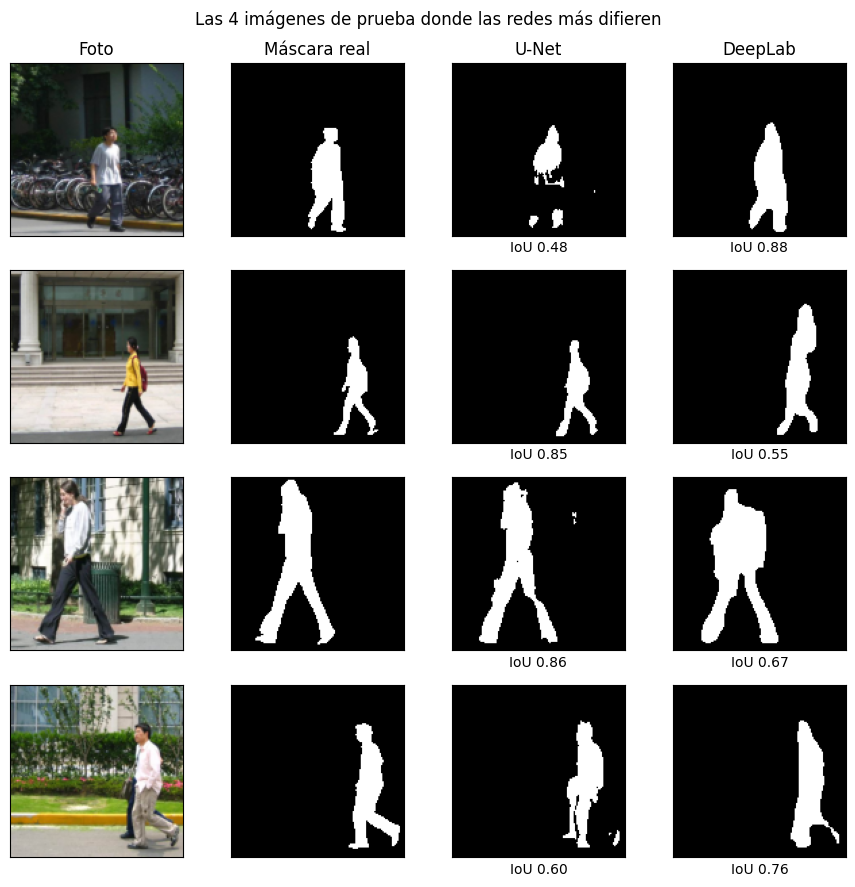

In [7]:
_, PU = evaluar(redes['U-Net'], Xte, Yte); _, PD = evaluar(redes['DeepLab'], Xte, Yte)
def iou_img(P):
    p = (P > .5).float(); return ((p*Yte).sum((1,2,3)) / (((p+Yte) > 0).float().sum((1,2,3)) + 1e-6)).numpy()
iu, idp = iou_img(PU), iou_img(PD)
sel = np.argsort(-(np.abs(iu - idp)))[:4]      # las 4 imágenes donde más difieren
fig, ax = plt.subplots(4, 4, figsize=(9, 9))
for r, j in enumerate(sel):
    ax[r,0].imshow(X[idx_test[j]].transpose(1,2,0)); ax[r,1].imshow(Yte[j,0], cmap='gray')
    ax[r,2].imshow(PU[j,0] > .5, cmap='gray'); ax[r,3].imshow(PD[j,0] > .5, cmap='gray')
    ax[r,2].set_xlabel(f'IoU {iu[j]:.2f}'); ax[r,3].set_xlabel(f'IoU {idp[j]:.2f}')
    for c in range(4): ax[r,c].set_xticks([]); ax[r,c].set_yticks([])
for c, t in enumerate(['Foto', 'Máscara real', 'U-Net', 'DeepLab']): ax[0,c].set_title(t)
plt.suptitle('Las 4 imágenes de prueba donde las redes más difieren'); plt.tight_layout(); plt.show()

## 8. Para Reportar

1. ¿Cuál red alcanza mejor IoU con el mismo número de épocas? ¿Cuál tiene más parámetros y cuál tardó más? la U-Net procesa mapas de 128 x 128 con muchos canales; DeepLab trabaja a 1/8 de resolución casi todo el tiempo.
2. Mira los bordes de las máscaras. ¿Cuál red los dibuja más nítidos? Relaciona con las skip connections de cada nivel (U-Net) frente a una sola (DeepLab).
3. Con solo 136 imágenes de entrenamiento ambas redes parten de cero y sobreajustan. ¿Qué cambiaría si el codificador viniera preentrenado en ImageNet (como en el DeepLabv3+ original)?
4. Prueba `EPOCAS = 60`, o cambia las tasas de ASPP `(1, 2, 4)` a `(1, 3, 6)`. ¿Qué cambia?

**Límites honestos.** Es un experimento didáctico: una sola semilla, 34 imágenes de prueba, redes con unos pocos cientos de miles de parámetros y solo una clase. Una diferencia pequeña de IoU entre las redes puede ser ruido. Las cifras de los artículos originales usan redes mucho más grandes y conjuntos de datos distintos.

## Referencias
- Ronneberger, O., Fischer, P., Brox, T. (2015). *U-Net: Convolutional Networks for Biomedical Image Segmentation*. MICCAI. arXiv:1505.04597.
- Chen, L.-C., Papandreou, G., Kokkinos, I., Murphy, K., Yuille, A. (2018). *DeepLab: Semantic Image Segmentation with Deep Convolutional Nets, Atrous Convolution, and Fully Connected CRFs*. IEEE TPAMI. arXiv:1606.00915.
- Chen, L.-C., Zhu, Y., Papandreou, G., Schroff, F., Adam, H. (2018). *Encoder-Decoder with Atrous Separable Convolution for Semantic Image Segmentation* (DeepLabv3+). ECCV. arXiv:1802.02611.
- Wang, L., Shi, J., Song, G., Shen, I. (2007). *Object Detection Combining Recognition and Segmentation*. ACCV. Datos: Penn-Fudan Database for Pedestrian Detection and Segmentation.

## 9. Experimento adicional — ASPP (1, 3, 6)

4. Prueba `EPOCAS = 60`, o cambia las tasas de ASPP `(1, 2, 4)` a `(1, 3, 6)`. ¿Qué cambia?

Ejecución NUEVA local en CPU, no Colab. Se conserva íntegramente el prefijo original. Ejecutar exclusivamente las celdas añadidas; no usar «Ejecutar todo», pues volvería a entrenar las referencias. No se recuperó checkpoint original. Se mantiene el procedimiento de normalización original (incluye prueba), con la limitación metodológica documentada en el informe. La semilla 42 de esta corrida no reconstruye la secuencia aleatoria de la corrida original.

Fontconfig error: No writable cache directories
torch 2.15.0+cpu | hilos CPU: 2
Descargando (~50 MB)...
Entrenamiento: 136 imágenes | Prueba (nunca vistas): 34
Fracción de píxeles que son persona: 17.3%  (por eso el IoU es mejor medida que la exactitud)
Nueva ejecución; parámetros: 507697
Época 01: pérdida 1.212758; IoU prueba 0.311563
Época 02: pérdida 0.959012; IoU prueba 0.391884
Época 03: pérdida 0.800819; IoU prueba 0.458334
Época 04: pérdida 0.687116; IoU prueba 0.451725
Época 05: pérdida 0.635486; IoU prueba 0.515161
Época 06: pérdida 0.598721; IoU prueba 0.482536
Época 07: pérdida 0.566179; IoU prueba 0.530482
Época 08: pérdida 0.530468; IoU prueba 0.549654
Época 09: pérdida 0.486654; IoU prueba 0.581886
Época 10: pérdida 0.462279; IoU prueba 0.549785
Época 11: pérdida 0.465099; IoU prueba 0.532727
Época 12: pérdida 0.431298; IoU prueba 0.567990
Época 13: pérdida 0.434513; IoU prueba 0.556286
Época 14: pérdida 0.428160; IoU prueba 0.550536
Época 15: pérdida 0.425090; IoU prueba

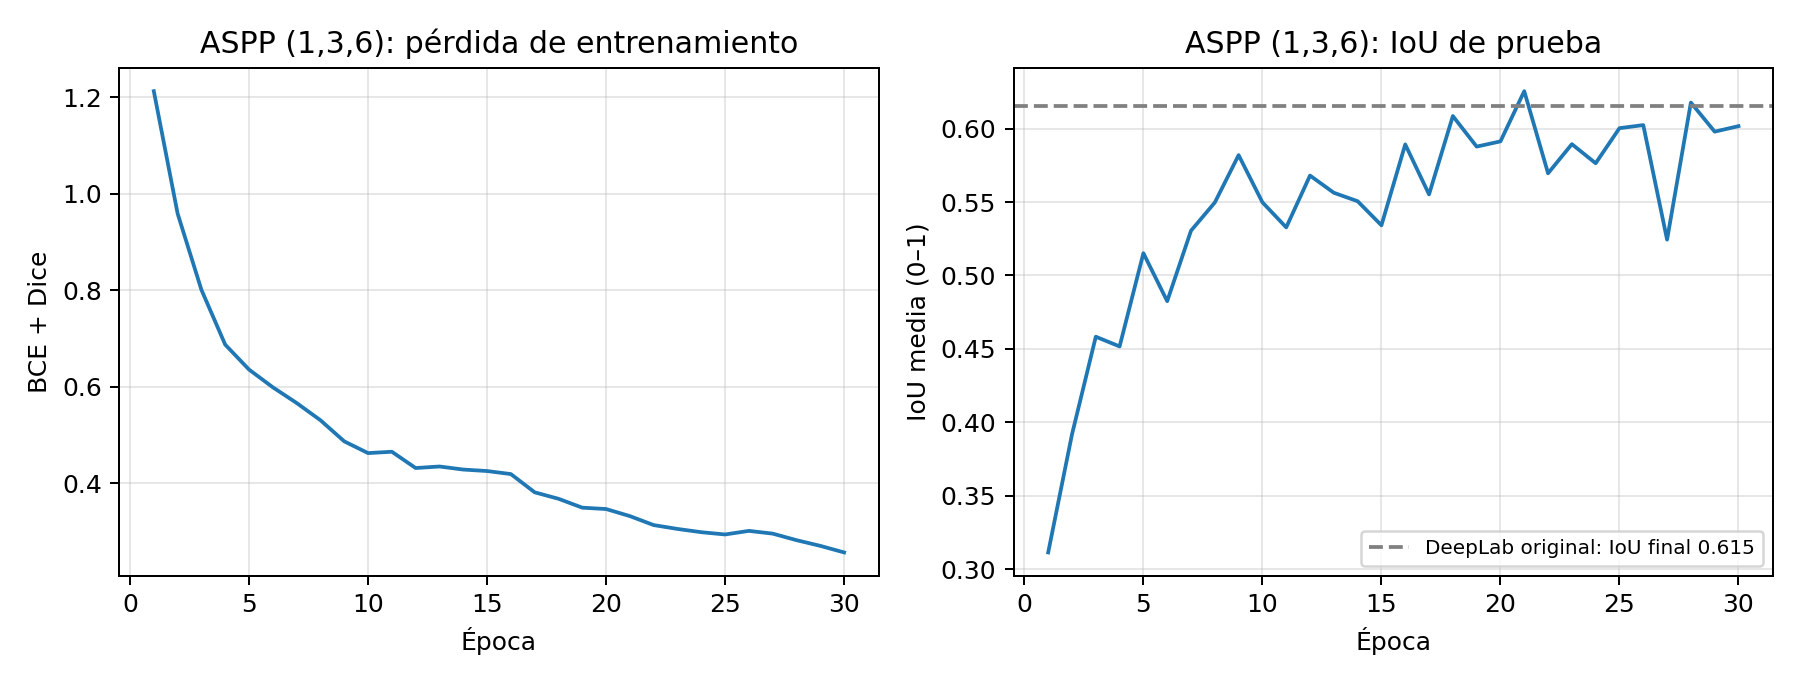

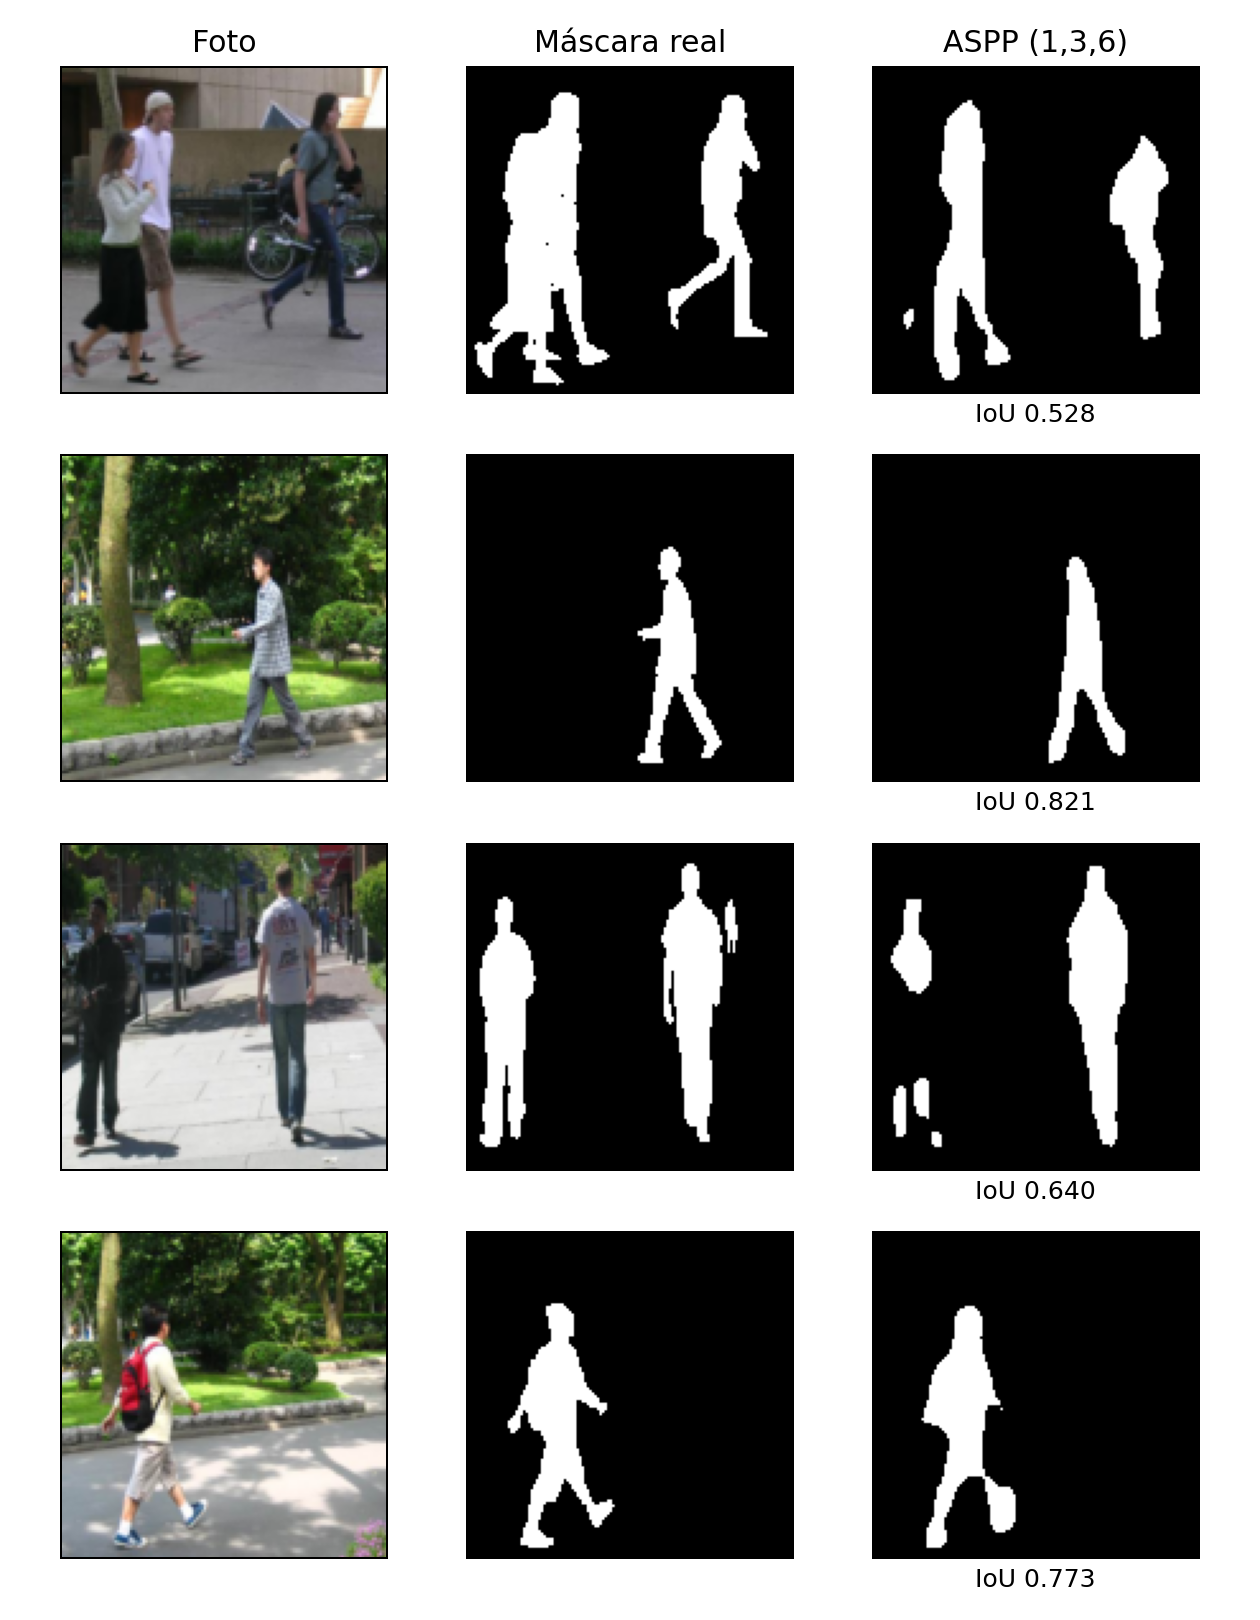

In [1]:
import os, time, zipfile, urllib.request, random
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
torch.set_num_threads(2)
print('torch', torch.__version__, '| hilos CPU:', torch.get_num_threads())
URL = 'https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip'
if not os.path.exists('PennFudanPed'):
    print('Descargando (~50 MB)...')
    urllib.request.urlretrieve(URL, 'PennFudanPed.zip')
    zipfile.ZipFile('PennFudanPed.zip').extractall('.')

T = 128
nombres = sorted(f[:-4] for f in os.listdir('PennFudanPed/PNGImages') if f.endswith('.png'))
X = np.zeros((len(nombres), 3, T, T), np.float32)
Y = np.zeros((len(nombres), 1, T, T), np.float32)
for i, n in enumerate(nombres):
    im = Image.open(f'PennFudanPed/PNGImages/{n}.png').convert('RGB').resize((T, T), Image.BILINEAR)
    mk = Image.open(f'PennFudanPed/PedMasks/{n}_mask.png').resize((T, T), Image.NEAREST)
    X[i] = np.asarray(im, np.float32).transpose(2, 0, 1) / 255.0
    Y[i, 0] = (np.asarray(mk) > 0)
media, desv = X.mean((0, 2, 3), keepdims=True), X.std((0, 2, 3), keepdims=True)
Xn = (X - media) / desv

rng = np.random.RandomState(SEMILLA); orden = rng.permutation(len(nombres))
n_test = 34
idx_test, idx_train = orden[:n_test], orden[n_test:]
Xtr, Ytr = torch.tensor(Xn[idx_train]), torch.tensor(Y[idx_train])
Xte, Yte = torch.tensor(Xn[idx_test]), torch.tensor(Y[idx_test])
print(f'Entrenamiento: {len(idx_train)} imágenes | Prueba (nunca vistas): {len(idx_test)}')
print(f'Fracción de píxeles que son persona: {Y.mean():.1%}  (por eso el IoU es mejor medida que la exactitud)')


def bloque(i, o, d=1):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=d, dilation=d, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(s, c=16):
        super().__init__()
        s.e1 = nn.Sequential(bloque(3, c), bloque(c, c))
        s.e2 = nn.Sequential(bloque(c, 2*c), bloque(2*c, 2*c))
        s.e3 = nn.Sequential(bloque(2*c, 4*c), bloque(4*c, 4*c))
        s.e4 = nn.Sequential(bloque(4*c, 8*c), bloque(8*c, 8*c))
        s.u3 = nn.ConvTranspose2d(8*c, 4*c, 2, 2); s.d3 = nn.Sequential(bloque(8*c, 4*c), bloque(4*c, 4*c))
        s.u2 = nn.ConvTranspose2d(4*c, 2*c, 2, 2); s.d2 = nn.Sequential(bloque(4*c, 2*c), bloque(2*c, 2*c))
        s.u1 = nn.ConvTranspose2d(2*c, c, 2, 2);   s.d1 = nn.Sequential(bloque(2*c, c), bloque(c, c))
        s.sal = nn.Conv2d(c, 1, 1)
    def forward(s, x):
        a = s.e1(x)                      # 128x128
        b = s.e2(F.max_pool2d(a, 2))     # 64x64
        c_ = s.e3(F.max_pool2d(b, 2))    # 32x32
        d = s.e4(F.max_pool2d(c_, 2))    # 16x16 (cuello de botella)
        y = s.d3(torch.cat([s.u3(d), c_], 1))
        y = s.d2(torch.cat([s.u2(y), b], 1))
        y = s.d1(torch.cat([s.u1(y), a], 1))
        return s.sal(y)

class ASPP(nn.Module):
    def __init__(s, i, o, tasas=(1, 2, 4)):
        super().__init__()
        s.ramas = nn.ModuleList([nn.Sequential(nn.Conv2d(i, o, 1 if r == 1 else 3, padding=0 if r == 1 else r,
                                                         dilation=r, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True)) for r in tasas])
        s.glob = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(i, o, 1, bias=False), nn.ReLU(inplace=True))
        s.mezcla = nn.Sequential(nn.Conv2d(o*(len(tasas)+1), o, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(s, x):
        g = F.interpolate(s.glob(x), size=x.shape[2:], mode='bilinear', align_corners=False)
        return s.mezcla(torch.cat([r(x) for r in s.ramas] + [g], 1))

class DeepLabMini(nn.Module):
    def __init__(s, c=16):
        super().__init__()
        s.stem = nn.Sequential(nn.Conv2d(3, c, 3, 2, 1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True), bloque(c, c))   # 1/2
        s.b2 = nn.Sequential(nn.Conv2d(c, 2*c, 3, 2, 1, bias=False), nn.BatchNorm2d(2*c), nn.ReLU(inplace=True), bloque(2*c, 2*c))  # 1/4 (bajo nivel)
        s.b3 = nn.Sequential(nn.Conv2d(2*c, 4*c, 3, 2, 1, bias=False), nn.BatchNorm2d(4*c), nn.ReLU(inplace=True), bloque(4*c, 4*c))  # 1/8
        s.dil = nn.Sequential(bloque(4*c, 8*c, d=2), bloque(8*c, 8*c, d=4))   # sigue en 1/8 pero con campo receptivo grande
        s.aspp = ASPP(8*c, 4*c)
        s.bajo = nn.Sequential(nn.Conv2d(2*c, c, 1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True))
        s.dec = nn.Sequential(bloque(4*c + c, 2*c), bloque(2*c, 2*c))
        s.sal = nn.Conv2d(2*c, 1, 1)
    def forward(s, x):
        H, W = x.shape[2:]
        bajo = s.b2(s.stem(x))                       # 1/4
        y = s.aspp(s.dil(s.b3(bajo)))                # 1/8
        y = F.interpolate(y, size=bajo.shape[2:], mode='bilinear', align_corners=False)
        y = s.dec(torch.cat([y, s.bajo(bajo)], 1))   # 1/4
        return F.interpolate(s.sal(y), size=(H, W), mode='bilinear', align_corners=False)

def n_param(m): return sum(p.numel() for p in m.parameters())

EPOCAS = 30
LOTE = 8
def perdida(logit, y):
    bce = F.binary_cross_entropy_with_logits(logit, y)
    p = torch.sigmoid(logit)
    dice = 1 - (2*(p*y).sum((1, 2, 3)) + 1) / (p.sum((1, 2, 3)) + y.sum((1, 2, 3)) + 1)
    return bce + dice.mean()

@torch.no_grad()
def evaluar(m, X, Y):
    m.eval(); P = torch.cat([torch.sigmoid(m(X[i:i+16])) for i in range(0, len(X), 16)])
    pred = (P > 0.5).float()
    inter = (pred*Y).sum((1, 2, 3)); union = ((pred+Y) > 0).float().sum((1, 2, 3))
    iou = (inter/(union+1e-6)).mean().item()
    return iou, P


# Ejecución NUEVA: solo DeepLab con ASPP (1,3,6); no se entrena la referencia.
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
modelo = DeepLabMini()
modelo.aspp = ASPP(128, 64, tasas=(1,3,6))
opt = torch.optim.Adam(modelo.parameters(), lr=3e-3)
registro = {'iou': [], 'perd': [], 'seg': 0.0}
print('Nueva ejecución; parámetros:', n_param(modelo), flush=True)
for ep in range(1,31):
    perm=torch.randperm(len(Xtr)); modelo.train(); total=0; t0=time.perf_counter()
    for i in range(0,len(perm),LOTE):
        b=perm[i:i+LOTE]; x,y=Xtr[b],Ytr[b]
        if random.random()<0.5: x,y=x.flip(3),y.flip(3)
        opt.zero_grad(); loss=perdida(modelo(x),y); loss.backward(); opt.step(); total+=loss.item()*len(b)
    registro['seg']+=time.perf_counter()-t0
    iou,P=evaluar(modelo,Xte,Yte)
    registro['iou'].append(iou); registro['perd'].append(total/len(Xtr))
    print(f'Época {ep:02d}: pérdida {registro["perd"][-1]:.6f}; IoU prueba {iou:.6f}',flush=True)
pred=(P>.5).float(); inter=(pred*Yte).sum((1,2,3)); union=((pred+Yte)>0).sum((1,2,3))
por_imagen=(inter/(union+1e-6)).numpy()
rng_boot=np.random.RandomState(2026)
medias=por_imagen[rng_boot.randint(0,len(por_imagen),(10000,len(por_imagen)))].mean(1)
registro.update(parametros=n_param(modelo),iou_por_imagen=por_imagen.tolist(),ic95_media_bootstrap=np.quantile(medias,[.025,.975]).tolist(),torch=torch.__version__,tasas=[1,3,6],semilla=42)
import json
with open('resultados.json','w') as f: json.dump(registro,f,indent=2)
torch.save(modelo.state_dict(),'deeplab_aspp_136.pt')
fig,ax=plt.subplots(1,2,figsize=(10,3.8))
ax[0].plot(range(1,31),registro['perd']); ax[0].set(title='ASPP (1,3,6): pérdida de entrenamiento',xlabel='Época',ylabel='BCE + Dice')
ax[1].plot(range(1,31),registro['iou']); ax[1].axhline(.615,color='gray',linestyle='--',label='DeepLab original: IoU final 0.615'); ax[1].set(title='ASPP (1,3,6): IoU de prueba',xlabel='Época',ylabel='IoU media (0–1)'); ax[1].legend(fontsize=8)
for a in ax: a.grid(alpha=.3)
fig.tight_layout(); fig.savefig('experimental_curvas.png',dpi=180); plt.close(fig)
fig,ax=plt.subplots(4,3,figsize=(7,9))
for j in range(4):
    ax[j,0].imshow(X[idx_test[j]].transpose(1,2,0)); ax[j,1].imshow(Yte[j,0],cmap='gray'); ax[j,2].imshow(pred[j,0],cmap='gray'); ax[j,2].set_xlabel(f'IoU {por_imagen[j]:.3f}')
    for a in ax[j]: a.set_xticks([]); a.set_yticks([])
for a,t in zip(ax[0],['Foto','Máscara real','ASPP (1,3,6)']): a.set_title(t)
fig.tight_layout(); fig.savefig('experimental_predicciones.png',dpi=180); plt.close(fig)
print(json.dumps(registro,ensure_ascii=False),flush=True)

from IPython.display import display, Image as Imagen
display(Imagen(filename="experimental_curvas.png"))
display(Imagen(filename="experimental_predicciones.png"))


### Resultados y límites

IoU final: 0.601611; mejor IoU observado en prueba: 0.625416. Este máximo es descriptivo y no se usa para seleccionar checkpoint. Tiempo de entrenamiento: 0.512 min. IC bootstrap del promedio final: [0.5367, 0.6635], condicionado a este modelo y a estas 34 imágenes; no mide variabilidad entre entrenamientos ni el efecto causal de cambiar ASPP.

La referencia DeepLab original tiene IoU final 0.615 (valor publicado redondeado). No se prueba una mejora causal: cambia la trayectoria aleatoria y la versión de PyTorch. No se entrenaron modelos originales ni controles nuevos. No se implementó la alternativa de 60 épocas porque el enunciado permite elegir.